# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3388 Дубровин Данила Николаевич. Вариант №5.


## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.


## Основные теоретические положения

### Линейные дискретные системы и разностные уравнения
Линейная стационарная дискретная система (ЛДС) с постоянными коэффициентами описывается разностным уравнением:
$$\sum_{k=0}^{K} a_k y[n-k] = \sum_{i=0}^{I} b_i x[n-i], \qquad a_0 = 1.$$

Связь между входным $x[n]$ и выходным $y[n]$ сигналами в комплексной $Z$-области устанавливается с помощью прямого $Z$-преобразования при нулевых начальных условиях. На основании свойства линейности и теоремы о задержке ($\mathcal{Z}\{y[n-k]\} = z^{-k} Y(z)$) уравнение преобразуется к виду:
$$Y(z) \sum_{k=0}^{K} a_k z^{-k} = X(z) \sum_{i=0}^{I} b_i z^{-i}.$$

Отсюда передаточная функция системы $H(z)$ определяется как отношение $Z$-образов выходного и входного сигналов:
$$H(z) = \frac{Y(z)}{X(z)} = \frac{\sum_{i=0}^{I} b_i z^{-i}}{\sum_{k=0}^{K} a_k z^{-k}}.$$

Для рекурсивного звена 2-го порядка ($I = K = 2$):
$$H(z) = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2}}{a_0 + a_1 z^{-1} + a_2 z^{-2}}.$$

Возвращаясь во временную область при $a_0 = 1$, получаем рекуррентную формулу для вычисления текущего отсчёта реакции:
$$y[n] = b_0 x[n] + b_1 x[n-1] + b_2 x[n-2] - a_1 y[n-1] - a_2 y[n-2].$$

### Временные характеристики и дискретная свёртка
Основными временными характеристиками системы являются:
* **Импульсная характеристика** $h[n]$ — реакция системы на единичный импульс $x[n] = \delta[n] = [1, 0, 0, \dots]$ при нулевых начальных условиях. В $Z$-области $h[n]$ является оригиналом передаточной функции $H(z)$. Для устойчивых рекурсивных звеньев импульсная характеристика бесконечна, однако её отсчёты быстро затухают.
* **Переходная характеристика** $g[n]$ — реакция системы на единичный скачок $u_1[n]$, связанная с импульсной характеристикой операцией накопления:
$$g[n] = \sum_{k=0}^{n} h[k].$$

Реакция системы на произвольное входное воздействие $x[n]$ вычисляется с помощью линейной дискретной свёртки входного сигнала с импульсной характеристикой:
$$y[n] = x[n] * h[n] = \sum_{m=0}^{\infty} x[m] h[n-m].$$
При свёртке двух массивов конечной длины $N_1$ и $N_2$ результирующая последовательность содержит $L = N_1 + N_2 - 1$ отсчётов.

### Нули, полюсы и частотный отклик
Дробно-рациональную передаточную функцию можно представить в факторизованной форме через нули $z_i$ (корни числителя) и полюсы $p_k$ (корни знаменателя):
$$H(z) = \frac{\prod_{i} (1 - z_i z^{-1})}{\prod_{k} (1 - p_k z^{-1})}.$$

* **Критерий устойчивости:** причинная система устойчива тогда и только тогда, когда все её полюсы лежат строго внутри единичной окружности на комплексной $Z$-плоскости: $|p_k| < 1$.
* Аргумент полюса в полярной форме $p = |p|e^{j\varphi}$ определяет нормированную резонансную частоту звена: $\widehat{\omega}_{\text{рез}} \approx \varphi$.

Частотная характеристика получается подстановкой $z = e^{j\widehat{\omega}}$:
$$H(e^{j\widehat{\omega}}) = |H(e^{j\widehat{\omega}})| e^{j\Phi(\widehat{\omega})},$$
где $A(\widehat{\omega}) = |H(e^{j\widehat{\omega}})|$ — амплитудно-частотная характеристика (АЧХ), а $\Phi(\widehat{\omega}) = \arg(H(e^{j\widehat{\omega}}))$ — фазочастотная характеристика (ФЧХ). В случае вещественных коэффициентов АЧХ симметрична относительно нуля, поэтому основной диапазон частот рассматривается на отрезке $\widehat{\omega} \in [0, \pi]$.

Связь между нормированной частотой $\widehat{\omega}$ (рад/отсчёт), физической частотой $f$ (Гц) и частотой дискретизации $f_d$:
$$\widehat{\omega} = 2\pi \frac{f}{f_d}.$$

### Дискретное преобразование Фурье и спектральный анализ
При равномерной дискретизации непрерывного сигнала с шагом $T = 1/f_d$ формируется последовательность $x[n] = x(nT)$, где $n = 0, 1, \dots, N-1$ — дискретное время (номер отсчёта), $t_n = nT = n/f_d$ — физическое время в секундах, а $\widehat{t} = n/N$ — дискретное нормированное время.

Прямое и обратное дискретное преобразование Фурье (ДПФ и ОДПФ) для блока из $N$ отсчётов определяются формулами:
$$X[k] = \sum_{n=0}^{N-1} x[n] e^{-j\frac{2\pi}{N} kn}, \qquad x[n] = \frac{1}{N} \sum_{k=0}^{N-1} X[k] e^{j\frac{2\pi}{N} kn}, \qquad k = 0, \dots, N-1.$$

Отсчёты $X[k]$ задают спектральный состав сигнала: модуль $|X[k]|$ и фазовый спектр $\arg(X[k])$. Для периодической последовательности коэффициенты комплексного ряда Фурье $C[k]$ связаны со значениями ДПФ нормирующим множителем $N$:
$$C[k] = \frac{X[k]}{N} \iff |X[k]| = N \cdot |C[k]|.$$
Двусторонний амплитудный спектр $|C[k]|$ гармонического сигнала $A\cos(2\pi f t + \varphi)$ содержит две спектральные линии амплитудой $A/2$ на положительной и отрицательной частотах.

Номеру гармоники $k$ соответствуют следующие частотные шкалы:
$$f_k = k \frac{f_d}{N}, \qquad \nu_k = \frac{k}{N}, \qquad \widehat{\omega}_k = 2\pi \nu_k.$$

### Восстановление аналогового сигнала и равенство Парсеваля
Если частота дискретизации удовлетворяет условию теоремы Котельникова ($f_d \ge 2 f_{\max}$), непрерывный сигнал однозначно восстанавливается интерполяцией тригонометрическим рядом Фурье по центрированным отсчётам ДПФ $X_a[k]$:
$$x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a[k] e^{j\frac{2\pi}{NT} kt}.$$
Массив $X_a[k]$ формируется циклическим сдвигом спектра ДПФ так, чтобы отрицательным частотам $k \in [-N/2, -1]$ соответствовали отсчёты второй половины ДПФ: $X_a[k] = X[N+k]$.

Равенство Парсеваля выражает фундаментальный закон сохранения энергии:
$$\sum_{n=0}^{N-1} |x[n]|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X[k]|^2.$$
Оно показывает, что энергия сигнала во временной области $E_{\text{время}}$ равна энергии в частотной области $E_{\text{частота}}$. Преобразование Фурье унитарно: оно сохраняет полную энергию сигнала, перераспределяя её по спектральным составляющим.


## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

В первой части требуется получить импульсную характеристику звена второго порядка, вычислить реакцию двумя способами, найти нули и полюсы и исследовать частотные характеристики. Во второй части требуется найти ДПФ суммы двух гармоник, выполнить обратное преобразование, сопоставить спектры конечной и периодической последовательностей, восстановить аналоговый сигнал и проверить равенство Парсеваля.

### Параметры варианта 5

Для первой части при $V=5$:

| Параметр | Формула задания | Значение |
|---|---|---|
| $b_0$ | $0.5+0.02V$ | $0.6$ |
| $b_1$ | $b_0(-1)^{V+1}(0.9822+0.0178V)$ | $0.64272$ |
| $b_2$ | $b_0(0.8+0.2(V\bmod 5))$ | $0.48$ |
| $a_0$ | $1$ | $1$ |
| $a_1$ | $(-1)^V(0.7778+0.025V)$ | $-0.9028$ |
| $a_2$ | $0.64+0.006V$ | $0.67$ |
| $N_1$ | $V\bmod 10+20$ | $25$ |
| $N_2$ | $V\bmod 10+30$ | $35$ |
| $f_{s,1}$ | $1000V$ | $5000$ Гц |

Для второй части:

| Параметр | Формула задания | Значение |
|---|---|---|
| $N$ | $64$ | $64$ |
| $f_{s,2}$ | $2000(V\bmod 5+1)$ | $2000$ Гц |
| $T$ | $1/f_{s,2}$ | $0.0005$ с |
| $A_1$ | $1+0.01V$ | $1.05$ |
| $A_2$ | $2A_1$ | $2.1$ |
| $f_1$ | $f_{s,2}/8$ | $250$ Гц |
| $f_2$ | $1.5f_1$ | $375$ Гц |



## Выполнение работы

### Подготовка


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

np.set_printoptions(precision=8, suppress=True)
plt.rcParams.update({"figure.figsize": (10, 3.5), "font.size": 11})

variant = 5
b0 = 0.5 + 0.02 * variant
b = np.array([
    b0,
    b0 * (-1)**(variant + 1) * (0.9822 + 0.0178 * variant),
    b0 * (0.8 + 0.2 * (variant % 5)),
])
a = np.array([1.0, (-1)**variant * (0.7778 + 0.025 * variant),
              0.64 + 0.006 * variant])
N1 = variant % 10 + 20
N2 = variant % 10 + 30
fs1 = 1000 * variant

print("b =", b)
print("a =", a)
print(f"N1 = {N1}; N2 = {N2}; fs1 = {fs1} Гц")


b = [0.6     0.64272 0.48   ]
a = [ 1.     -0.9028  0.67  ]
N1 = 25; N2 = 35; fs1 = 5000 Гц


### Часть 1. Линейная дискретная система

#### 1. Импульсная характеристика

После подстановки коэффициентов получается

$$H(z)=\frac{0.6+0.64272z^{-1}+0.48z^{-2}}{1-0.9028z^{-1}+0.67z^{-2}}.$$

Для аналитического выражения удобно сначала рассмотреть систему с единичным числителем. Полюсы знаменателя имеют вид $p_{1,2}=re^{\pm j\phi}$, где

$$r=\sqrt{0.67},\qquad \phi=\arccos\frac{0.9028}{2r}.$$

Тогда

$$g[n]=\frac{p_1^{n+1}-p_2^{n+1}}{p_1-p_2}=r^n\frac{\sin((n+1)\phi)}{\sin\phi},\qquad n\geq0,$$

а при $n<0$ полагается $g[n]=0$. Умножение на числитель даёт

$$\boxed{h[n]=0.6g[n]+0.64272g[n-1]+0.48g[n-2].}$$

Эта формула учитывает нулевые начальные условия. Первые $N_1=25$ отсчётов вычисляются как реакция на единичный импульс и сравниваются с аналитическим выражением.


r = 0.81853528; phi/pi = 0.31406602
Первые четыре отсчёта h: [0.6        1.1844     1.14727632 0.24221306]
Ошибка аналитической формулы: 2.220e-16


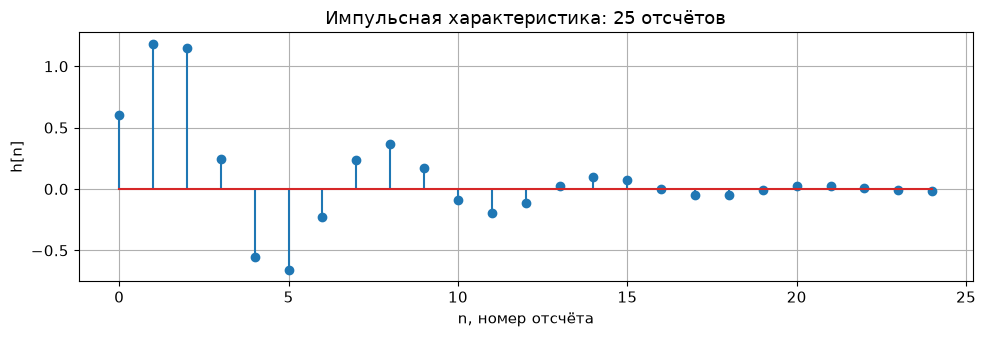

In [2]:
n_h = np.arange(N1)
delta = np.zeros(N1)
delta[0] = 1
h = signal.lfilter(b, a, delta)

r = np.sqrt(a[2])
phi = np.arccos(-a[1] / (2 * r))

def g(n):
    n = np.asarray(n)
    return np.where(n >= 0, r**n * np.sin((n + 1) * phi) / np.sin(phi), 0.0)

h_formula = sum(b[i] * g(n_h - i) for i in range(3))
error_h = np.max(np.abs(h - h_formula))
assert np.allclose(h, h_formula, atol=1e-12, rtol=0)
print(f"r = {r:.8f}; phi/pi = {phi / np.pi:.8f}")
print("Первые четыре отсчёта h:", h[:4])
print(f"Ошибка аналитической формулы: {error_h:.3e}")

plt.figure()
plt.stem(n_h, h)
plt.xlabel("n, номер отсчёта")
plt.ylabel("h[n]")
plt.title("Импульсная характеристика: 25 отсчётов")
plt.grid()
plt.tight_layout()
plt.show()


#### 2. Реакция по формуле свёртки

При округлении положительной половины вверх длительность импульса равна

$$M=\left\lfloor\frac{N_2}{2}+0.5\right\rfloor=\lfloor18\rfloor=18.$$

Таким образом, задаётся массив длины $N_2=35$:

$$x[n]=\begin{cases}1,&0\leq n<18,\\0,&18\leq n\leq34.\end{cases}$$

Ненулевая часть содержит 18 отсчётов. Реакция $y_1[n]$ получается свёрткой этого массива с усечённой ИХ $h_{25}[n]$.


Длина массива x: 35; ненулевых отсчётов: 18
Длина полной свёртки: 25 + 35 - 1 = 59
Последний ненулевой отсчёт свёртки: n = 41


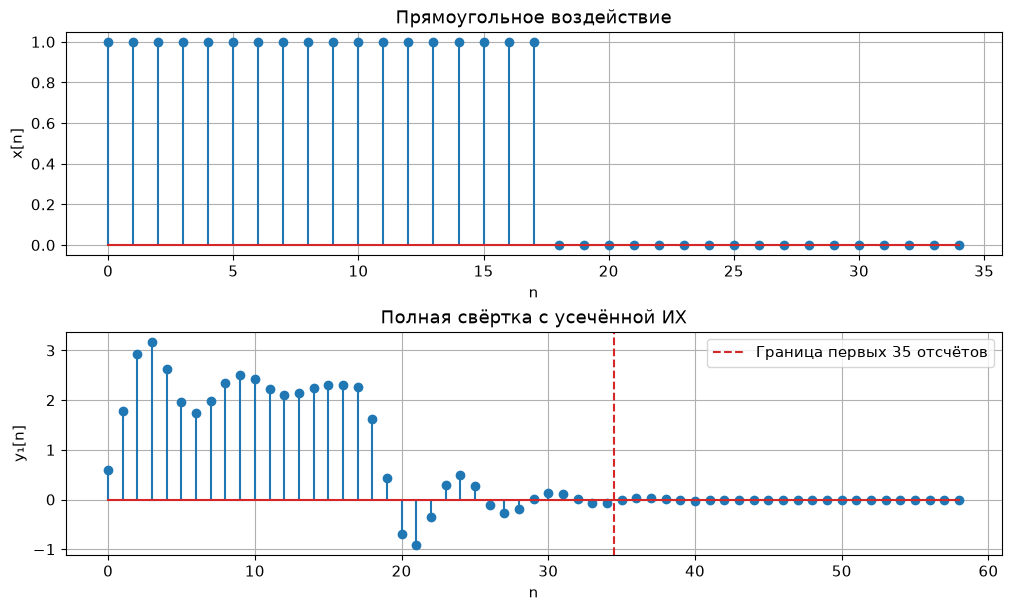

In [3]:
n_x = np.arange(N2)
pulse_length = int(np.floor(N2 / 2 + 0.5))
x1 = (n_x < pulse_length).astype(float)
y1_full = np.convolve(x1, h, mode="full")
y1 = y1_full[:N2]
nonzero = np.flatnonzero(np.abs(y1_full) > 1e-12)
print(f"Длина массива x: {len(x1)}; ненулевых отсчётов: {pulse_length}")
print(f"Длина полной свёртки: {N1} + {N2} - 1 = {len(y1_full)}")
print(f"Последний ненулевой отсчёт свёртки: n = {nonzero[-1]}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(n_x, x1)
axes[0].set(xlabel="n", ylabel="x[n]", title="Прямоугольное воздействие")
axes[1].stem(np.arange(len(y1_full)), y1_full)
axes[1].axvline(N2 - 0.5, color="tab:red", ls="--", label="Граница первых 35 отсчётов")
axes[1].set(xlabel="n", ylabel="y₁[n]", title="Полная свёртка с усечённой ИХ")
axes[1].legend()
for ax in axes:
    ax.grid()
plt.show()


Полная линейная свёртка массивов имеет длину $25+35-1=59$. На графике представлены индексы $0,\ldots,58$. Из-за нулевого окончания входного массива ненулевая часть свёртки короче: $25+18-1=42$ отсчёта, то есть $n=0,\ldots,41$. Последние 17 отсчётов равны нулю.

Для сравнения с разностным уравнением берём первые $N_2=35$ отсчётов свёртки. В реальности реакция на этом не обрывается: так как импульсная характеристика бесконечна, затухающие колебания продолжаются и дальше.

#### 3. Реакция по разностному уравнению

Передаточной функции соответствует уравнение

$$\boxed{y_2[n]=0.9028y_2[n-1]-0.67y_2[n-2]+0.6x[n]+0.64272x[n-1]+0.48x[n-2].}$$

Отсчёты с отрицательными индексами равны нулю. Рекурсия вычисляется последовательно, а результат проверяется функцией `lfilter`.


Ошибка сравнения до n = 24: 1.110e-15
Максимальное расхождение на 35 отсчётах: 0.01067293
Первое расхождение y2[25] - y1[25]: -0.00614892


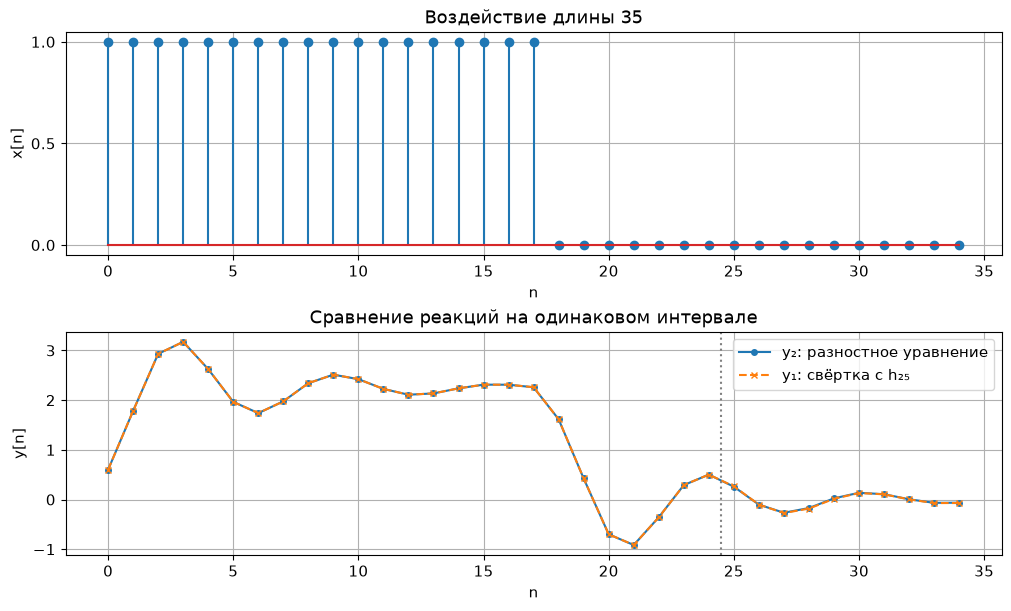

In [4]:
y2 = np.zeros(N2)
for n in range(N2):
    for i in range(3):
        if n >= i:
            y2[n] += b[i] * x1[n - i]
    for i in range(1, 3):
        if n >= i:
            y2[n] -= a[i] * y2[n - i]

assert np.allclose(y2, signal.lfilter(b, a, x1), atol=1e-12, rtol=0)
error_before_cut = np.max(np.abs(y1[:N1] - y2[:N1]))
error_response = np.max(np.abs(y1 - y2))
assert error_before_cut < 1e-12
print(f"Ошибка сравнения до n = {N1 - 1}: {error_before_cut:.3e}")
print(f"Максимальное расхождение на 35 отсчётах: {error_response:.8f}")
print(f"Первое расхождение y2[25] - y1[25]: {y2[25] - y1[25]:.8f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(n_x, x1)
axes[0].set(xlabel="n", ylabel="x[n]", title="Воздействие длины 35")
axes[0].set_yticks([0, 0.5, 1])
axes[1].plot(n_x, y2, "o-", label="y₂: разностное уравнение", markersize=4)
axes[1].plot(n_x, y1, "x--", label="y₁: свёртка с h₂₅", markersize=5)
axes[1].axvline(N1 - 0.5, color="gray", ls=":")
axes[1].set(xlabel="n", ylabel="y[n]", title="Сравнение реакций на одинаковом интервале")
axes[1].legend()
for ax in axes:
    ax.grid()
plt.show()


Первые 25 отсчётов двух реакций совпадают с точностью округления.

Оба способа описывают одну и ту же систему, а небольшое расхождение далее возникает только из-за усечения импульсной характеристики до 25 отсчётов. Если продолжить вычисление по рекуррентной формуле дальше при нулевом входе, сигнал продолжит плавно затухать к нулю.

#### 4. Нули и полюсы

После умножения числителя и знаменателя на $z^2$ вычисляются корни многочленов $0.6z^2+0.64272z+0.48$ и $z^2-0.9028z+0.67$. Алгебраическая и показательная формы связаны равенствами

$$z=x+jy=\rho e^{j\theta},\qquad \rho=\sqrt{x^2+y^2},\quad \theta=\operatorname{atan2}(y,x).$$


In [5]:
zeros = np.roots(b)
poles = np.roots(a)
z_check, p_check, gain = signal.tf2zpk(b, a)
assert np.allclose(np.sort_complex(zeros), np.sort_complex(z_check))
assert np.allclose(np.sort_complex(poles), np.sort_complex(p_check))

print("Корень       Алгебраическая форма         Модуль       arg/pi")
for name, roots in [("z", zeros), ("p", poles)]:
    for i, root in enumerate(roots, 1):
        print(f"{name}{i}       {root.real:.8f}{root.imag:+.8f}j"
              f"     {abs(root):.8f}    {np.angle(root) / np.pi:+.8f}")
print(f"Множитель: {gain:.8f}")


Корень       Алгебраическая форма         Модуль       arg/pi
z1       -0.53560000+0.71633277j     0.89442719    +0.70436312
z2       -0.53560000-0.71633277j     0.89442719    -0.70436312
p1       0.45140000+0.68281626j     0.81853528    +0.31406602
p2       0.45140000-0.68281626j     0.81853528    -0.31406602
Множитель: 0.60000000


Получены следующие значения:

| Корни | Алгебраическая форма | Показательная форма |
|---|---|---|
| Нули $z_{1,2}$ | $-0.5356\pm j0.71633277$ | $0.89442719e^{\pm j0.70436312\pi}$ |
| Полюсы $p_{1,2}$ | $0.4514\pm j0.68281626$ | $0.81853528e^{\pm j0.31406602\pi}$ |

Полученные нули и полюсы образуют комплексно-сопряжённые пары. Запишем передаточную функцию в виде произведения простейших множителей:

$$H(z)\approx0.6\frac{(1-0.89442719e^{j0.70436312\pi}z^{-1})(1-0.89442719e^{-j0.70436312\pi}z^{-1})}{(1-0.81853528e^{j0.31406602\pi}z^{-1})(1-0.81853528e^{-j0.31406602\pi}z^{-1})}.$$


#### 5. Карта нулей и полюсов


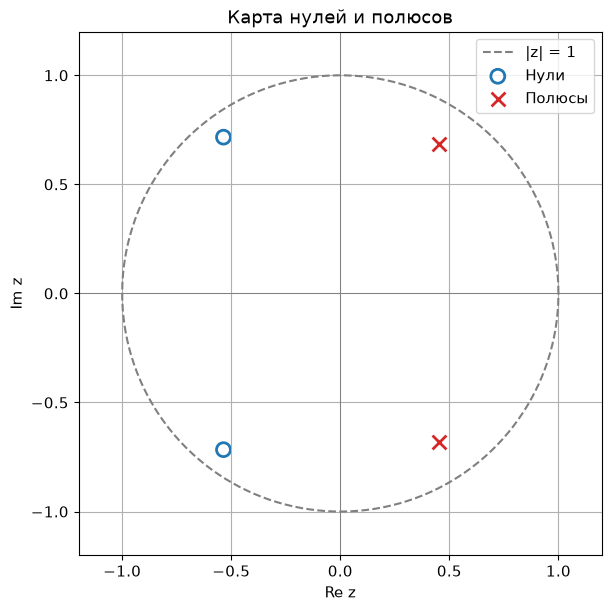

Модули полюсов: [0.81853528 0.81853528]
Система устойчива: True


In [6]:
circle_angle = np.linspace(0, 2 * np.pi, 500)
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
ax.plot(np.cos(circle_angle), np.sin(circle_angle), "--", color="gray", label="|z| = 1")
ax.scatter(zeros.real, zeros.imag, marker="o", s=100, facecolors="none",
           edgecolors="tab:blue", linewidths=2, label="Нули")
ax.scatter(poles.real, poles.imag, marker="x", s=100, color="tab:red",
           linewidths=2, label="Полюсы")
ax.axhline(0, color="gray", lw=0.7)
ax.axvline(0, color="gray", lw=0.7)
ax.set(xlabel="Re z", ylabel="Im z", title="Карта нулей и полюсов",
       xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
ax.grid()
ax.legend()
plt.show()
print("Модули полюсов:", np.abs(poles))
print("Система устойчива:", bool(np.all(np.abs(poles) < 1)))


И нули, и полюсы лежат внутри единичной окружности. На устойчивость фильтра влияют именно полюсы: так как их модуль $|p_{1,2}| = \sqrt{0.67} \approx 0.82 < 1$, система устойчива. Расположение точек на графике полностью подтверждает аналитический расчёт из п. 4.

#### 6. АЧХ и ФЧХ в шкале нормированной частоты

Частотная характеристика вычисляется на единичной окружности: $H(e^{j\widehat\omega})$. На графиках показана неотрицательная половина основной полосы, $0\leq\widehat\omega\leq\pi$, с осью $\widehat\omega/\pi$.


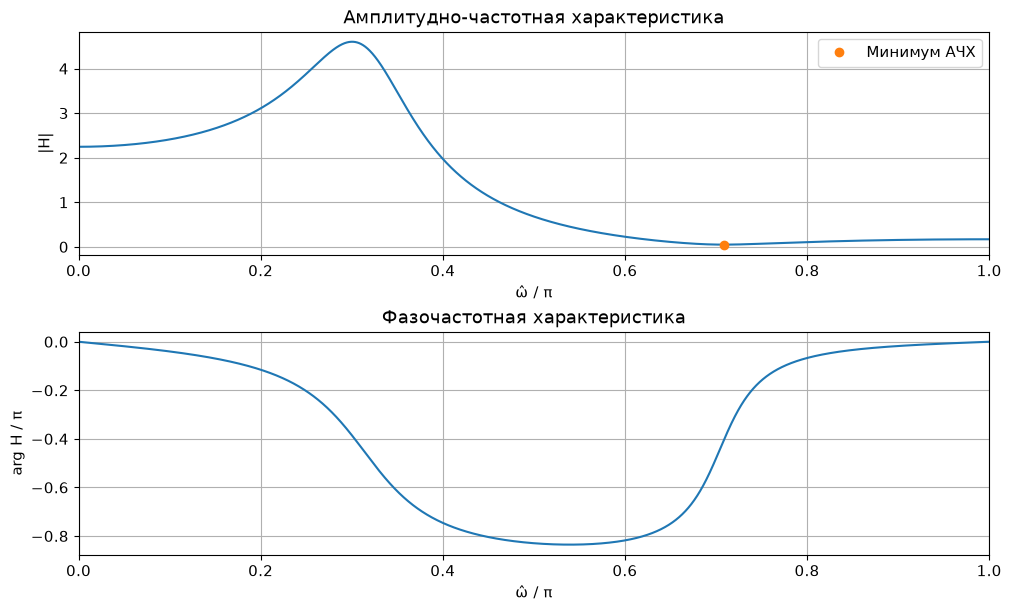

АЧХ на границах: |H(0)| = 2.24546403; |H(pi)| = 0.16996269
Максимум на сетке: 4.60276679 при omega/pi = 0.30041504
Минимум на сетке: 0.04972910 при omega/pi = 0.70855713
Наибольшее изменение фазы между соседними точками: 0.001691 рад


In [7]:
omega = np.linspace(0, np.pi, 16385)
_, H = signal.freqz(b, a, worN=omega)
magnitude = np.abs(H)
phase = np.angle(H)
peak = np.argmax(magnitude)
minimum = np.argmin(magnitude)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].plot(omega / np.pi, magnitude)
axes[0].plot(omega[minimum] / np.pi, magnitude[minimum], "o", label="Минимум АЧХ")
axes[0].set(ylabel="|H|", title="Амплитудно-частотная характеристика")
axes[0].legend()
axes[1].plot(omega / np.pi, phase / np.pi)
axes[1].set(ylabel="arg H / π", title="Фазочастотная характеристика")
for ax in axes:
    ax.set(xlabel="ω̂ / π", xlim=(0, 1))
    ax.grid()
plt.show()

print(f"АЧХ на границах: |H(0)| = {magnitude[0]:.8f}; |H(pi)| = {magnitude[-1]:.8f}")
print(f"Максимум на сетке: {magnitude[peak]:.8f} при omega/pi = {omega[peak] / np.pi:.8f}")
print(f"Минимум на сетке: {magnitude[minimum]:.8f} при omega/pi = {omega[minimum] / np.pi:.8f}")
print(f"Наибольшее изменение фазы между соседними точками: {np.max(np.abs(np.diff(phase))):.6f} рад")


**Выводы по графикам АЧХ и ФЧХ:**

* **Основная полоса частот:** $[0, \pi]$ (для систем с вещественными коэффициентами АЧХ чётная, поэтому достаточно рассматривать неотрицательные частоты).
* **Связь с картой нулей и полюсов:**
  * Полюсы (угол $\approx 0.31\pi$) вызывают пик усиления (максимум АЧХ) около частоты $\widehat{\omega} \approx 0.30\pi$.
  * Нули (угол $\approx 0.70\pi$) вызывают провал (минимум АЧХ) около частоты $\widehat{\omega} \approx 0.71\pi$.
* **Скачок фазы:** Скачка фазы на $\pi$ нет, так как нули лежат внутри окружности, а не строго на ней (АЧХ нигде не падает точно до нуля).
* **Подавление гармоник:** Фильтр сильнее всего подавляет высокочастотные составляющие входного сигнала в районе провала ($\widehat{\omega} \ge 0.7\pi$).

#### 7. АЧХ и ФЧХ в герцах

При $f_{s,1}=5000$ Гц выполняется $f=\widehat\omega f_{s,1}/(2\pi)$. Основная полоса равна $[-2500,2500)$ Гц. На графиках приведена её неотрицательная половина $[0,2500]$ Гц.


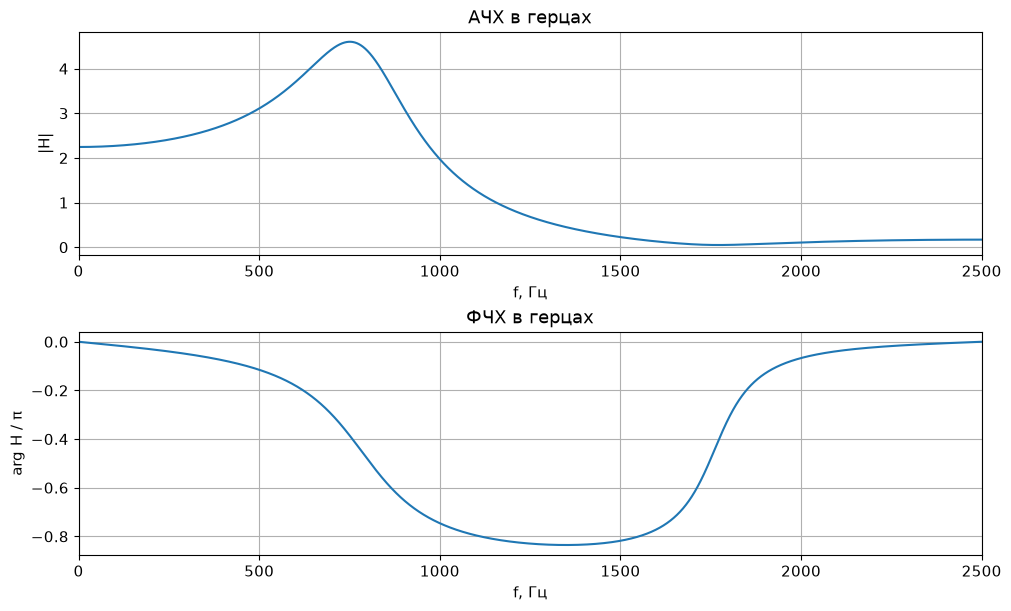

Частота максимума на сетке: 751.0376 Гц
Частота минимума на сетке: 1771.3928 Гц


In [8]:
frequency = omega * fs1 / (2 * np.pi)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].plot(frequency, magnitude)
axes[0].set(ylabel="|H|", title="АЧХ в герцах")
axes[1].plot(frequency, phase / np.pi)
axes[1].set(ylabel="arg H / π", title="ФЧХ в герцах")
for ax in axes:
    ax.set(xlabel="f, Гц", xlim=(0, fs1 / 2))
    ax.grid()
plt.show()
print(f"Частота максимума на сетке: {frequency[peak]:.4f} Гц")
print(f"Частота минимума на сетке: {frequency[minimum]:.4f} Гц")


Границам $\widehat\omega=0$ и $\widehat\omega=\pi$ соответствуют $f=0$ и $f=2500$ Гц. Резонанс находится примерно при 751 Гц, минимум АЧХ — примерно при 1771 Гц. Значения АЧХ и ФЧХ при переходе к герцам сохраняются; меняется только частотная шкала.


### Часть 2. Дискретное преобразование Фурье

#### 1. Исходная последовательность

Для варианта 5 исходная последовательность определяется формулой

$$x[n]=1.05\cos(2\pi\cdot250nT+\pi/4)+2.1\cos(2\pi\cdot375nT+\pi/8),\qquad 0\leq n<64,$$

где $T=0.0005$ с. В нормированном времени это

$$x[n]=1.05\cos(\pi n/4+\pi/4)+2.1\cos(3\pi n/8+\pi/8).$$

Дискретное физическое время равно $t_n=nT$, нормированное время — $t_n/T=n$. Заданный период $N=64$ соответствует $NT=0.032$ с. Минимальный период суммы равен 16 отсчётам, или $0.008$ с: первая гармоника имеет период 8 отсчётов, вторая — 16. Поэтому выбранный блок содержит четыре минимальных периода.


fs2 = 2000 Гц; T = 0.0005 с; NT = 0.032 с
A1 = 1.05; A2 = 2.1; f1 = 250.0 Гц; f2 = 375.0 Гц


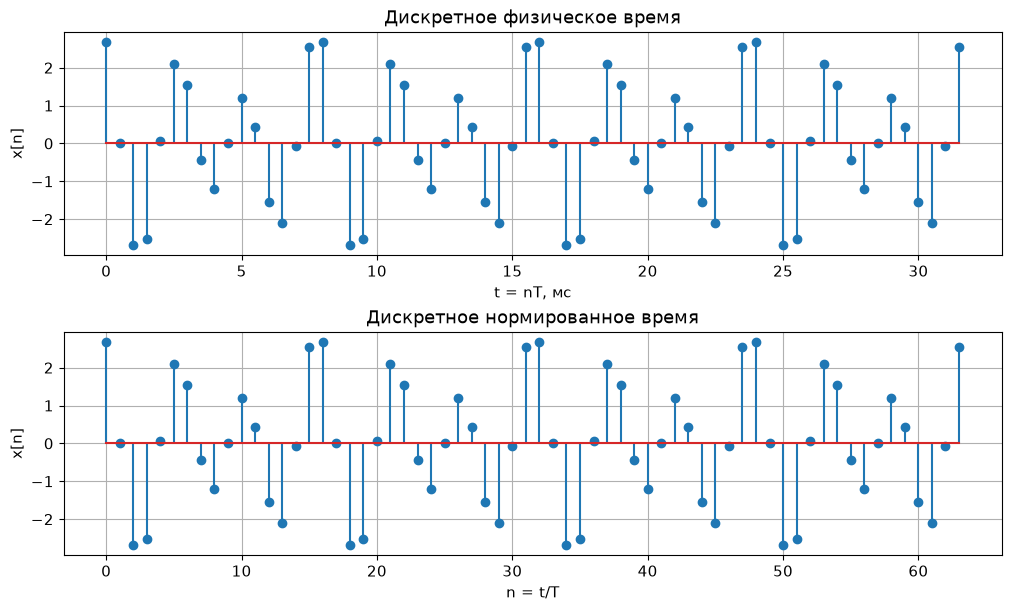

In [9]:
N = 64
fs2 = 2000 * (variant % 5 + 1)
T = 1 / fs2
A1 = 1 + 0.01 * variant
A2 = 2 * A1
f1 = fs2 / 8
f2 = 1.5 * f1
n2 = np.arange(N)
t_samples = n2 * T
x2 = (A1 * np.cos(2 * np.pi * f1 * t_samples + np.pi / 4)
      + A2 * np.cos(2 * np.pi * f2 * t_samples + np.pi / 8))
print(f"fs2 = {fs2} Гц; T = {T} с; NT = {N * T} с")
print(f"A1 = {A1}; A2 = {A2}; f1 = {f1} Гц; f2 = {f2} Гц")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(t_samples * 1000, x2)
axes[0].set(xlabel="t = nT, мс", ylabel="x[n]", title="Дискретное физическое время")
axes[1].stem(n2, x2)
axes[1].set(xlabel="n = t/T", ylabel="x[n]", title="Дискретное нормированное время")
for ax in axes:
    ax.grid()
plt.show()


#### 2. ДПФ и обратное преобразование


Максимальная ошибка ОДПФ: 6.106e-16
Максимальная мнимая часть: 1.110e-16


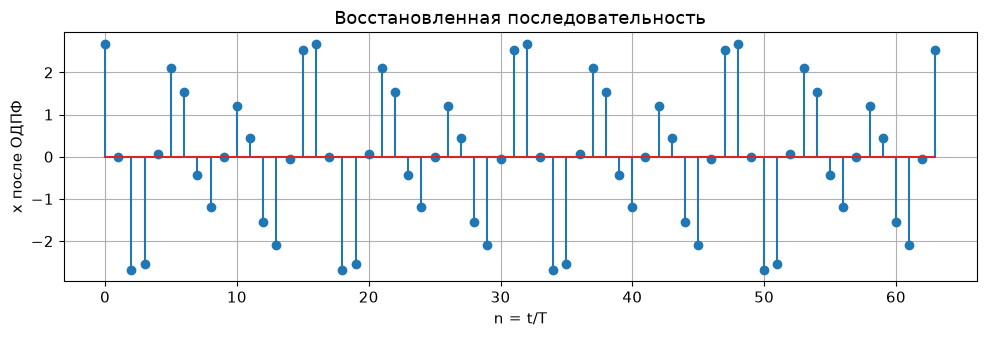

In [10]:
X = np.fft.fft(x2)
x_inverse = np.fft.ifft(X)
error_inverse = np.max(np.abs(x_inverse - x2))
assert error_inverse < 1e-12
print(f"Максимальная ошибка ОДПФ: {error_inverse:.3e}")
print(f"Максимальная мнимая часть: {np.max(np.abs(x_inverse.imag)):.3e}")

plt.figure()
plt.stem(n2, x_inverse.real)
plt.xlabel("n = t/T")
plt.ylabel("x после ОДПФ")
plt.title("Восстановленная последовательность")
plt.grid()
plt.tight_layout()
plt.show()


ОДПФ точно восстанавливает исходный сигнал (погрешность на уровне машинной точности порядка $10^{-16}$). Мнимая часть практически равна нулю, так как исходная последовательность вещественная.

#### 3. Амплитудный и фазовый спектры

Для периодической последовательности вычисляются коэффициенты $C[k]=X[k]/N$. Спектры изображаются в центрированном порядке $k=-32,\ldots,31$, то есть отрицательные частоты находятся слева от нуля. Используется нормированная угловая частота $\widehat\omega_k=2\pi k/N$ и абсолютная частота $f_k=kf_{s,2}/N$.


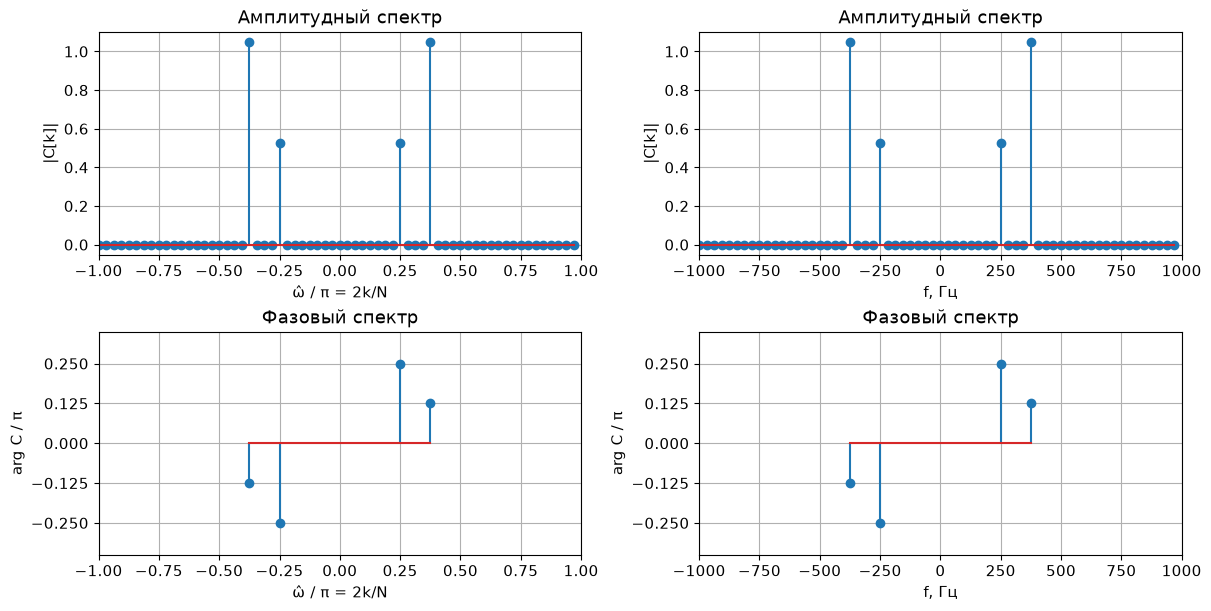

 k      f, Гц       |C[k]|      arg C / pi
-12     -375.00      1.05000     -0.12500
 -8     -250.00      0.52500     -0.25000
  8      250.00      0.52500     +0.25000
 12      375.00      1.05000     +0.12500


In [11]:
k_center = np.arange(-N // 2, N // 2)
nu_center = k_center / N
f_center = nu_center * fs2
C_center = np.fft.fftshift(X / N)
amplitude = np.abs(C_center)
active = amplitude > 1e-10 * np.max(amplitude)
phases = np.angle(C_center[active])

fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")
for col, (axis_values, axis_label) in enumerate([
    (2 * nu_center, "ω̂ / π = 2k/N"), (f_center, "f, Гц")
]):
    axes[0, col].stem(axis_values, amplitude)
    axes[0, col].set(xlabel=axis_label, ylabel="|C[k]|", title="Амплитудный спектр")
    axes[1, col].stem(axis_values[active], phases / np.pi)
    axes[1, col].set(xlabel=axis_label, ylabel="arg C / π", title="Фазовый спектр",
                     ylim=(-0.35, 0.35))
    axes[1, col].set_yticks([-0.25, -0.125, 0, 0.125, 0.25])
    for row in range(2):
        axes[row, col].set_xlim(axis_values[0], -axis_values[0])
for ax in axes.flat:
    ax.grid()
plt.show()

print(" k      f, Гц       |C[k]|      arg C / pi")
for k, f, c in zip(k_center[active], f_center[active], C_center[active]):
    print(f"{k:3d}    {f:8.2f}    {abs(c):9.5f}     {np.angle(c) / np.pi:+.5f}")


Нормированная частота в циклах на отсчёт равна $\nu_k=k/N$, нормированная угловая частота — $\widehat\omega_k=2\pi\nu_k$, абсолютная — $f_k=\nu_k f_{s,2}$. Частотный шаг составляет $\Delta f=2000/64=31.25$ Гц.

Ненулевые линии спектра:

| $k$ в центрированной шкале | $\nu=k/N$ | $f$, Гц | $\vert C[k]\vert$ | $\arg C[k]$ |
|---|---|---|---|---|
| $-12$ | $-3/16$ | $-375$ | $1.05$ | $-\pi/8$ |
| $-8$ | $-1/8$ | $-250$ | $0.525$ | $-\pi/4$ |
| $8$ | $1/8$ | $250$ | $0.525$ | $\pi/4$ |
| $12$ | $3/16$ | $375$ | $1.05$ | $\pi/8$ |

Частоты гармоник соответствуют целым индексам 8 и 12, поэтому растекания спектра нет. Для вещественной последовательности коэффициенты на противоположных частотах комплексно сопряжены: амплитудный спектр чётный, а фазовый нечётный на ненулевых линиях. В обычном порядке ДПФ отрицательным частотам соответствуют индексы 52 и 56. Фаза в точках с нулевой амплитудой не определена и на графиках не задаётся.


#### 4. ДПФ конечной последовательности

Тот же блок из $N=64$ отсчётов рассматривается как конечная последовательность, равная нулю вне $0\leq n<N$. Для независимой проверки ДПФ вычисляется непосредственно по определению. Сравниваются модуль ДПФ конечной последовательности и амплитуды ряда Фурье её периодического продолжения.


Ошибка прямого вычисления ДПФ относительно FFT: 4.707e-13
Ненулевые значения |X|: [67.2 33.6 33.6 67.2]


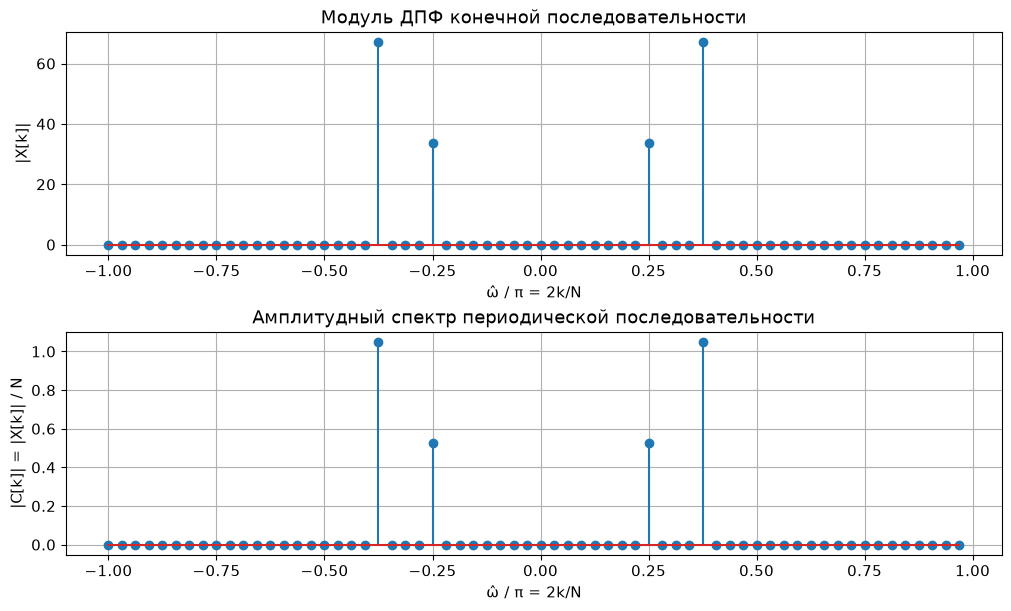

In [12]:
k_dft = np.arange(N)
dft_matrix = np.exp(-2j * np.pi * np.outer(k_dft, n2) / N)
X_finite = dft_matrix @ x2
error_dft = np.max(np.abs(X_finite - X))
assert np.allclose(X_finite, X, atol=1e-10, rtol=0)
print(f"Ошибка прямого вычисления ДПФ относительно FFT: {error_dft:.3e}")
print("Ненулевые значения |X|:", np.abs(np.fft.fftshift(X_finite))[active])

fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")
axes[0].stem(2 * nu_center, np.abs(np.fft.fftshift(X_finite)))
axes[0].set(ylabel="|X[k]|", title="Модуль ДПФ конечной последовательности")
axes[1].stem(2 * nu_center, amplitude)
axes[1].set(ylabel="|C[k]| = |X[k]| / N", title="Амплитудный спектр периодической последовательности")
for ax in axes:
    ax.set(xlabel="ω̂ / π = 2k/N")
    ax.grid()
plt.show()


Положения линий совпадают, поскольку рассматривается один и тот же массив отсчётов. Различие состоит в нормировке: $|X[k]|=N|C[k]|$. Поэтому высоты линий ДПФ равны $33.6$ и $67.2$, а амплитуды ряда Фурье — $0.525$ и $1.05$.

У конечной последовательности преобразование Фурье непрерывно по частоте, и ДПФ даёт значения этого преобразования в $N$ узлах. У периодического продолжения спектр линейчатый, с коэффициентами $C[k]=X[k]/N$.


#### 5. Восстановление аналогового сигнала

Восстановление выполняется по заданной формуле:

$$x_r(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a[k]\exp\left(j\frac{2\pi kt}{NT}\right),$$

$$X_a[k]=\begin{cases}X[N+k],&-N/2\leq k\leq-1,\\X[k],&0\leq k\leq N/2-1.\end{cases}$$

Значения времени задаются на $[0,(N-1)T]=[0,0.0315]$ с, включая обе границы, с шагом $\Delta t=T/4=0.000125$ с. Коэффициенты аналогового ряда Фурье равны $c_k=X_a[k]/N$.


Число точек: 253; шаг: 0.00012500 с
Конец интервала: 0.03150000 с = (N - 1)T
Ошибка восстановления на плотной сетке: 2.932e-14
Ошибка в исходных отсчётах: 2.065e-14
Максимальная мнимая часть: 1.038e-15


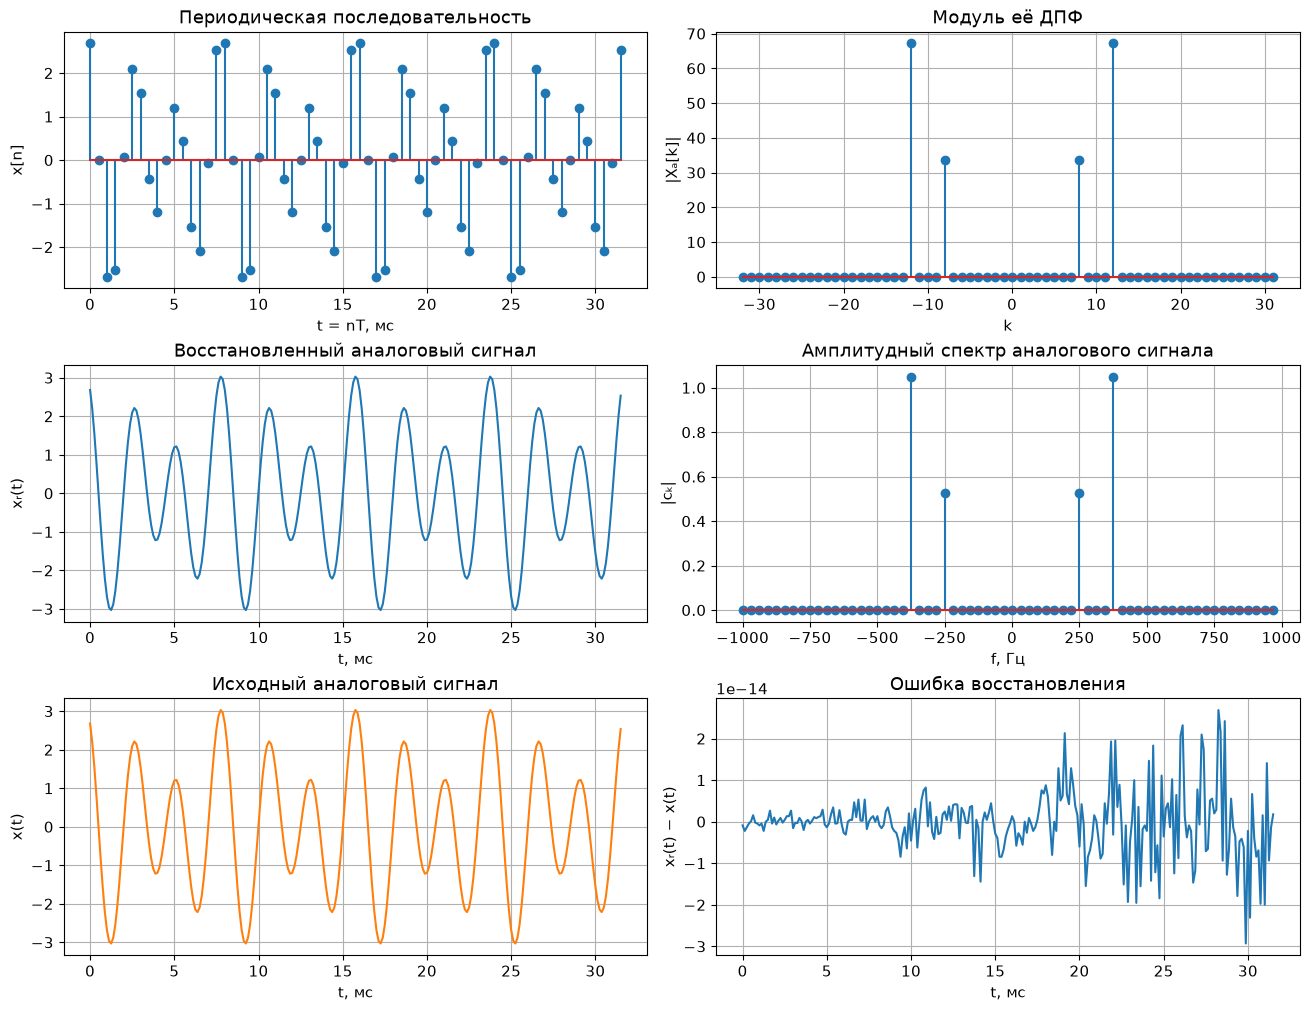

In [13]:
X_a = np.empty(N, dtype=complex)
for index, k in enumerate(k_center):
    X_a[index] = X[N + k] if k < 0 else X[k]
assert np.allclose(X_a, np.fft.fftshift(X), atol=1e-12, rtol=0)

t_dense = np.arange(4 * (N - 1) + 1) * (T / 4)
exponent = np.exp(2j * np.pi * np.outer(t_dense, k_center) / (N * T))
x_reconstructed = exponent @ X_a / N
x_original = (A1 * np.cos(2 * np.pi * f1 * t_dense + np.pi / 4)
              + A2 * np.cos(2 * np.pi * f2 * t_dense + np.pi / 8))
analog_amplitude = np.abs(X_a / N)
error_reconstruction = np.max(np.abs(x_reconstructed - x_original))
error_samples = np.max(np.abs(x_reconstructed[::4] - x2))
assert error_reconstruction < 1e-12
assert error_samples < 1e-12
print(f"Число точек: {len(t_dense)}; шаг: {T / 4:.8f} с")
print(f"Конец интервала: {t_dense[-1]:.8f} с = (N - 1)T")
print(f"Ошибка восстановления на плотной сетке: {error_reconstruction:.3e}")
print(f"Ошибка в исходных отсчётах: {error_samples:.3e}")
print(f"Максимальная мнимая часть: {np.max(np.abs(x_reconstructed.imag)):.3e}")

fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout="constrained")
axes[0, 0].stem(t_samples * 1000, x2)
axes[0, 0].set(xlabel="t = nT, мс", ylabel="x[n]", title="Периодическая последовательность")
axes[0, 1].stem(k_center, np.abs(X_a))
axes[0, 1].set(xlabel="k", ylabel="|Xₐ[k]|", title="Модуль её ДПФ")
axes[1, 0].plot(t_dense * 1000, x_reconstructed.real)
axes[1, 0].set(xlabel="t, мс", ylabel="xᵣ(t)", title="Восстановленный аналоговый сигнал")
axes[1, 1].stem(f_center, analog_amplitude)
axes[1, 1].set(xlabel="f, Гц", ylabel="|cₖ|", title="Амплитудный спектр аналогового сигнала")
axes[2, 0].plot(t_dense * 1000, x_original, color="tab:orange")
axes[2, 0].set(xlabel="t, мс", ylabel="x(t)", title="Исходный аналоговый сигнал")
axes[2, 1].plot(t_dense * 1000, x_reconstructed.real - x_original)
axes[2, 1].set(xlabel="t, мс", ylabel="xᵣ(t) − x(t)", title="Ошибка восстановления")
for ax in axes.flat:
    ax.grid()
plt.show()


#### 6. Интерпретация восстановления

Амплитудный спектр восстановленного непрерывного сигнала получается делением модуля ДПФ на $N = 64$ и циклическим сдвигом спектра (вторая половина массива переносится в область отрицательных частот).

В результате на частотах $\pm250$ и $\pm375$ Гц получаем спектральные линии с высотами $0.525$ и $1.05$ (что в сумме для каждой пары даёт амплитуды исходных косинусов $1.05$ и $2.1$).

Восстановленный и исходный сигналы визуально совпадают. Обе частоты ниже частоты Найквиста ($f_{s,2}/2 = 1000$ Гц), а выбранный блок содержит целое число периодов обеих гармоник, поэтому наложение спектров и растекание отсутствуют. Численная проверка подтверждает точное восстановление на всей временной сетке.

#### 7. Равенство Парсеваля

При используемой нормировке проверяется равенство

$$E_t=\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2=E_f.$$

Из ортогональности гармоник на рассматриваемом блоке также следует

$$E=\frac N2(A_1^2+A_2^2)=176.4,\qquad P=\frac EN=2.75625.$$


In [14]:
energy_time = np.sum(np.abs(x2)**2)
energy_frequency = np.sum(np.abs(X)**2) / N
energy_expected = N * (A1**2 + A2**2) / 2
power_fourier = np.sum(np.abs(X / N)**2)
assert np.isclose(energy_time, energy_frequency, atol=1e-10, rtol=0)
assert np.isclose(energy_time, energy_expected, atol=1e-10, rtol=0)
assert np.isclose(energy_time / N, power_fourier, atol=1e-12, rtol=0)
print(f"Энергия во временной области: {energy_time:.12f}")
print(f"Энергия в частотной области: {energy_frequency:.12f}")
print(f"Энергия по амплитудам гармоник: {energy_expected:.12f}")
print(f"Абсолютное расхождение: {abs(energy_time - energy_frequency):.3e}")
print(f"Средняя мощность: {power_fourier:.8f}")


Энергия во временной области: 176.400000000000
Энергия в частотной области: 176.400000000000
Энергия по амплитудам гармоник: 176.400000000000
Абсолютное расхождение: 2.842e-14
Средняя мощность: 2.75625000


Результаты совпадают с точностью машинных вычислений. Равенство Парсеваля показывает, что энергию можно вычислить по временным отсчётам или по коэффициентам ДПФ с учётом множителя $1/N$.

Значение $176.4$ является энергией конечного блока из 64 отсчётов. Для бесконечной периодической последовательности используется средняя мощность $P=2.75625$, которая также равна $\sum_k|C[k]|^2$.


## Выводы

В ходе работы исследованы линейная дискретная система 2-го порядка и дискретное преобразование Фурье:
* Аналитическая формула импульсной характеристики полностью совпала с численным расчётом. Звено устойчиво, так как модуль полюсов $|p| \approx 0.82 < 1$.
* Реакции, найденные через свёртку и по разностному уравнению, полностью совпадают на первых 25 отсчётах.
* Полюсы создают резонансный пик на АЧХ в районе 751 Гц, а нули — провал около 1771 Гц (фильтр сильнее всего ослабляет высокие частоты).
* ДПФ суммы гармоник 250 и 375 Гц дало 4 спектральные линии с ожидаемыми амплитудами и фазами. Обратное ДПФ восстанавливает отсчёты с машинной точностью, а тригонометрический ряд Фурье точно интерполирует непрерывный сигнал.
* Равенство Парсеваля строго подтверждено: энергия во временной и частотной областях совпадает ($E = 176.4$, средняя мощность $P \approx 2.76$).